问题一

模型系数_线性       变量     Coef.  Std.Err.          t         P>|t|    [0.025    0.975]
0  const  0.119377  0.011168  10.689432  2.031544e-25  0.097464  0.141290
1    孕周数  0.001254  0.000247   5.069200  4.699089e-07  0.000769  0.001740
2    BMI -0.001960  0.000339  -5.776880  9.950005e-09 -0.002626 -0.001295
模型系数_二次交互       变量     Coef.  Std.Err.         t     P>|t|    [0.025        0.975]
0  const  0.038716  0.075354  0.513786  0.607507 -0.109142  1.865743e-01
1    孕周数 -0.006468  0.003296 -1.962213  0.049995 -0.012935 -1.300295e-07
2    BMI  0.006852  0.003934  1.741791  0.081831 -0.000867  1.457174e-02
3   孕周数2  0.000118  0.000066  1.785254  0.074502 -0.000012  2.472526e-04
4   BMI2 -0.000160  0.000058 -2.763657  0.005813 -0.000273 -4.631185e-05
5     交互  0.000108  0.000080  1.339994  0.180530 -0.000050  2.650841e-04
模型总体指标对比       模型        R2    Adj-R2          AIC          BIC  F检验p值
0     线性  0.045545  0.043774 -4318.556651 -4303.599726    0.0
1  二次+交互  0.056318  0.051929 -4324.828375 

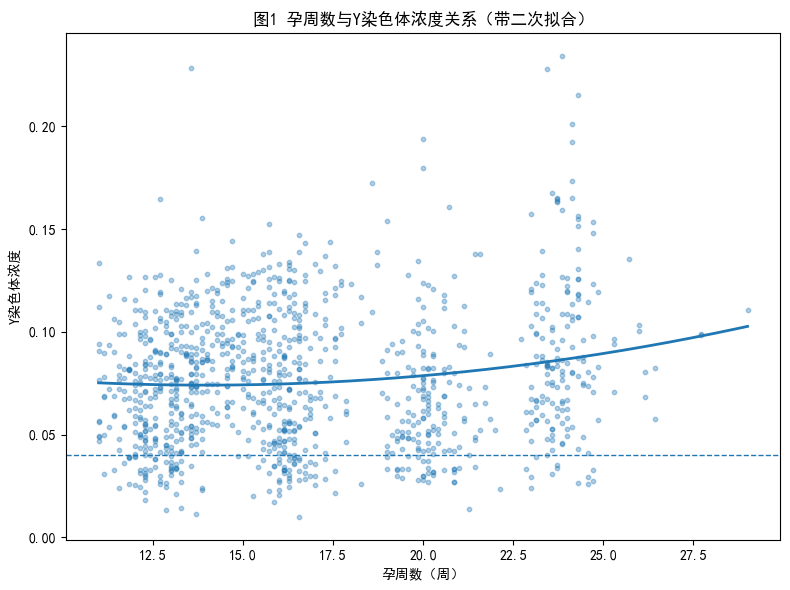

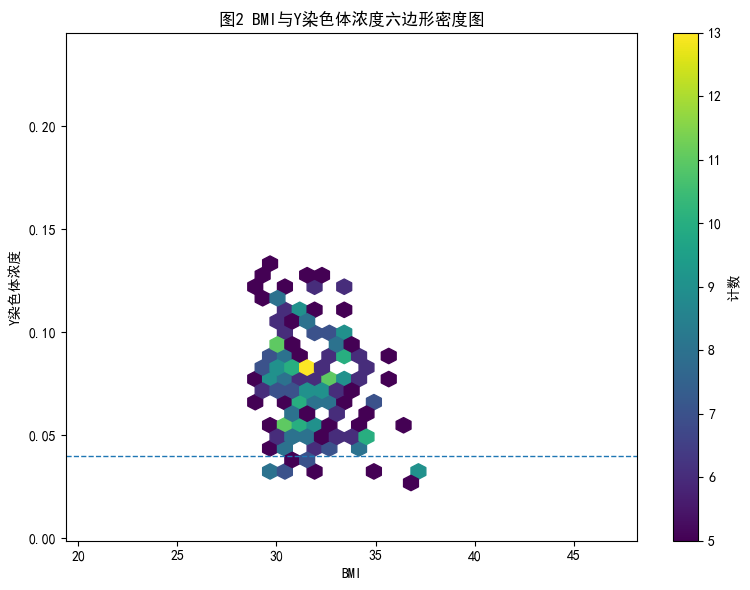

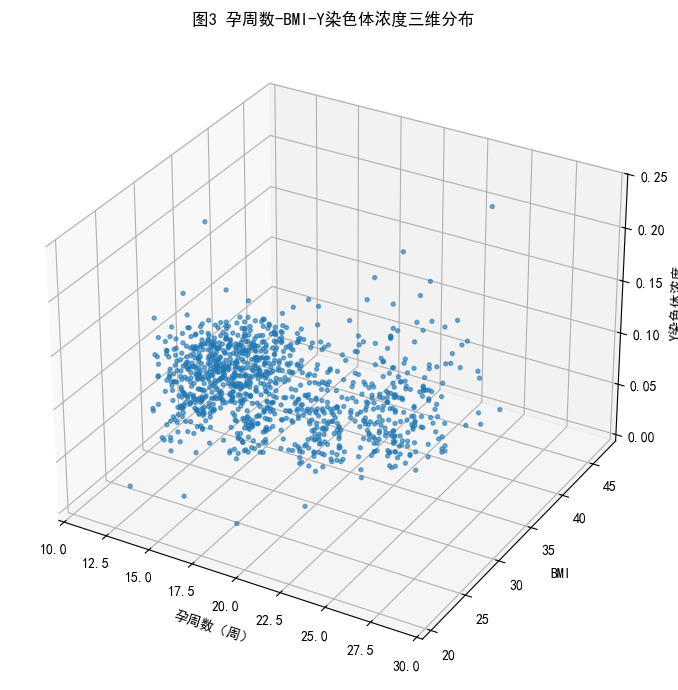

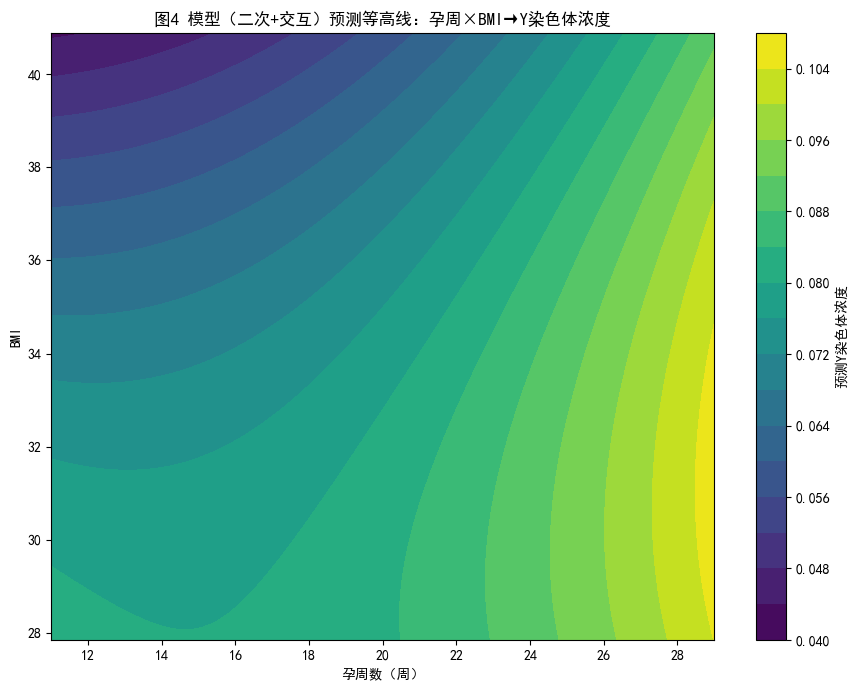

女胎表无 Y染色体浓度 列，符合预期（女胎无Y染色体）。
按BMI分位的首达4%孕周（模型推断）    BMI分位   BMI值  预测首达4%孕周
0   0.10  29.13      11.0
1   0.25  30.20      11.0
2   0.50  31.80      11.0
3   0.75  33.91      11.0
4   0.90  36.13      11.0


In [5]:
# -*- coding: utf-8 -*-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from mpl_toolkits.mplot3d import Axes3D

# 中文显示
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus']=False

# 读取两张表
file_path = r"D:\desk\CUMCM2025Problems\C题\附件.xlsx"
male = pd.read_excel(file_path, sheet_name="男胎检测数据")
female = pd.read_excel(file_path, sheet_name="女胎检测数据")

# 统一预处理函数
def week_to_float(w):
    if isinstance(w, str) and "w" in w:
        try:
            w0, d = w.split("w")
            d = d.replace("+","")
            d = int(d) if d else 0
            return int(w0) + d/7.0
        except:
            return np.nan
    try:
        return float(w)
    except:
        return np.nan

def with_bmi(df):
    df = df.copy()
    df["BMI"] = df["体重"] / ((df["身高"]/100.0)**2)
    df["孕周数"] = df["检测孕周"].apply(week_to_float)
    return df

male = with_bmi(male)
female = with_bmi(female)

# ———— 仅对男胎做 Y 染色体浓度分析 ————
m = male[["孕周数","BMI","Y染色体浓度"]].dropna().copy()

# 线性模型
X_lin = sm.add_constant(m[["孕周数","BMI"]])
y = m["Y染色体浓度"]
lin_model = sm.OLS(y, X_lin).fit()

# 二次 & 交互模型
m["孕周数2"] = m["孕周数"]**2
m["BMI2"] = m["BMI"]**2
m["交互"] = m["孕周数"]*m["BMI"]
X_quad = sm.add_constant(m[["孕周数","BMI","孕周数2","BMI2","交互"]])
quad_model = sm.OLS(y, X_quad).fit()

# 将关键指标整理为表格
coef_lin = lin_model.summary2().tables[1].reset_index().rename(columns={"index":"变量"})
coef_quad = quad_model.summary2().tables[1].reset_index().rename(columns={"index":"变量"})

metrics = pd.DataFrame({
    "模型":["线性","二次+交互"],
    "R2":[lin_model.rsquared, quad_model.rsquared],
    "Adj-R2":[lin_model.rsquared_adj, quad_model.rsquared_adj],
    "AIC":[lin_model.aic, quad_model.aic],
    "BIC":[lin_model.bic, quad_model.bic],
    "F检验p值":[lin_model.f_pvalue, quad_model.f_pvalue]
})

print("模型系数_线性", coef_lin)
print("模型系数_二次交互", coef_quad)
print("模型总体指标对比", metrics.round(6))

# 选择较优模型用于可视化（以更高的Adj-R2为准）
best = quad_model if quad_model.rsquared_adj >= lin_model.rsquared_adj else lin_model
best_name = "二次+交互" if best is quad_model else "线性"

# —— 图1：孕周 vs Y（散点 + 多项式拟合曲线）——
plt.figure(figsize=(8,6))
plt.scatter(m["孕周数"], m["Y染色体浓度"], s=10, alpha=0.35)
# 二次多项式拟合（仅基于孕周）
p = np.polyfit(m["孕周数"], m["Y染色体浓度"], 2)
xx = np.linspace(m["孕周数"].min(), m["孕周数"].max(), 200)
yy = p[0]*xx**2 + p[1]*xx + p[2]
plt.plot(xx, yy, linewidth=2)
plt.axhline(0.04, linestyle="--", linewidth=1)  # 4%阈值
plt.title("图1 孕周数与Y染色体浓度关系（带二次拟合）")
plt.xlabel("孕周数（周）")
plt.ylabel("Y染色体浓度")
plt.tight_layout()
plt.show()

# —— 图2：BMI vs Y（六边形密度图，展示高BMI对Y浓度的压制）——
plt.figure(figsize=(8,6))
hb = plt.hexbin(m["BMI"], m["Y染色体浓度"], gridsize=35, mincnt=5)
cb = plt.colorbar(hb)
cb.set_label("计数")
plt.axhline(0.04, linestyle="--", linewidth=1)
plt.title("图2 BMI与Y染色体浓度六边形密度图")
plt.xlabel("BMI")
plt.ylabel("Y染色体浓度")
plt.tight_layout()
plt.show()

# —— 图3：三维散点（孕周、BMI 与 Y）——
fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(m["孕周数"], m["BMI"], m["Y染色体浓度"], s=8, alpha=0.6)
ax.set_title("图3 孕周数-BMI-Y染色体浓度三维分布")
ax.set_xlabel("孕周数（周）")
ax.set_ylabel("BMI")
ax.set_zlabel("Y染色体浓度")
plt.tight_layout()
plt.show()

# —— 图4：基于最优模型的预测等高线（周×BMI 网格）——
# 构造网格
w_grid = np.linspace(m["孕周数"].min(), m["孕周数"].max(), 80)
b_grid = np.linspace(m["BMI"].quantile(0.01), m["BMI"].quantile(0.99), 80)
WW, BB = np.meshgrid(w_grid, b_grid)
if best is quad_model:
    Z = (best.params["const"]
         + best.params["孕周数"]*WW
         + best.params["BMI"]*BB
         + best.params["孕周数2"]*(WW**2)
         + best.params["BMI2"]*(BB**2)
         + best.params["交互"]*(WW*BB))
else:
    Z = (best.params["const"]
         + best.params["孕周数"]*WW
         + best.params["BMI"]*BB)

plt.figure(figsize=(9,7))
cs = plt.contourf(WW, BB, Z, levels=18)
cbar = plt.colorbar(cs)
cbar.set_label("预测Y染色体浓度")
plt.contour(WW, BB, Z, levels=[0.04], linewidths=1.2)  # 4%阈值曲线
plt.title(f"图4 模型（{best_name}）预测等高线：孕周×BMI→Y染色体浓度")
plt.xlabel("孕周数（周）")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

# 女胎表可能没有 Y染色体浓度列
if "Y染色体浓度" in female.columns:
    f = female[["孕周数","BMI","Y染色体浓度"]].dropna()
    if len(f) > 0:
        check_stats = f["Y染色体浓度"].describe(percentiles=[0.5,0.9,0.99]).to_frame(name="女胎Y浓度分布")
        print(check_stats)
else:
    print("女胎表无 Y染色体浓度 列，符合预期（女胎无Y染色体）。")

# —— 推荐时点：按BMI四分位，求达到4%的最早孕周（基于最优模型）——
def earliest_week_for_threshold(bmi, y_thr=0.04):
    # 在可行范围内搜索周数
    ws = np.linspace(m["孕周数"].min(), m["孕周数"].max(), 500)
    if best is quad_model:
        yhat = (best.params["const"]
                + best.params["孕周数"]*ws
                + best.params["BMI"]*bmi
                + best.params["孕周数2"]*(ws**2)
                + best.params["BMI2"]*(bmi**2)
                + best.params["交互"]*(ws*bmi))
    else:
        yhat = (best.params["const"]
                + best.params["孕周数"]*ws
                + best.params["BMI"]*bmi)
    ws_ok = ws[yhat >= y_thr]
    return ws_ok.min() if ws_ok.size>0 else np.nan

bmi_quants = m["BMI"].quantile([0.1,0.25,0.5,0.75,0.9]).round(2)
rows = []
for label, bmi_v in bmi_quants.items():
    w_star = earliest_week_for_threshold(bmi_v)
    rows.append({"BMI分位":label, "BMI值":bmi_v, "预测首达4%孕周": None if pd.isna(w_star) else round(float(w_star),2)})
rec_table = pd.DataFrame(rows)
print("按BMI分位的首达4%孕周（模型推断）", rec_table)


问题二

q2_group_table.csv    组次           BMI区间  组内中位BMI  推荐NIPT孕周(满足90%达标)  在推荐孕周于上界BMI的失败率(%)  组内样本量
0   1  [28.52, 31.01)    29.77              11.00                9.98    359
1   2  [31.01, 32.59)    31.80              18.65               10.58    226
2   3  [32.59, 34.18)    33.39              20.25               10.82    195
3   4  [34.18, 35.77)    34.98              21.85               11.07    122
4   5  [35.77, 37.29]    36.53              23.40               11.26     67
q2_logit_coef.csv        变量      系数估计
0      常数 -4.363115
1      孕周 -0.110835
2     BMI  0.186108
3    孕周^2  0.001912
4   BMI^2 -0.003722
5  孕周×BMI  0.001792
q2_metrics.csv    残差标准差_logit      阈值z值         孕周范围        BMI范围
0     0.491393 -3.178054  11.00-29.00  20.70-46.87


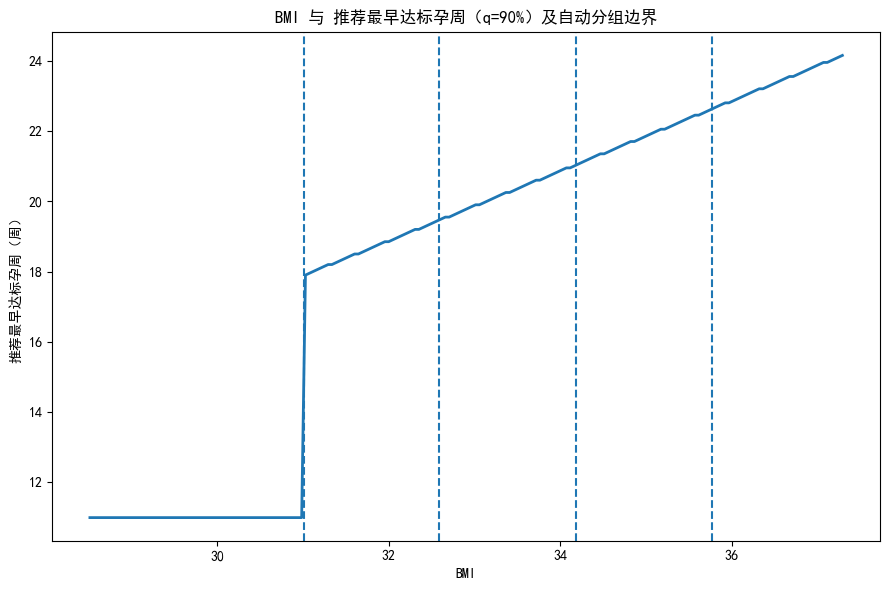

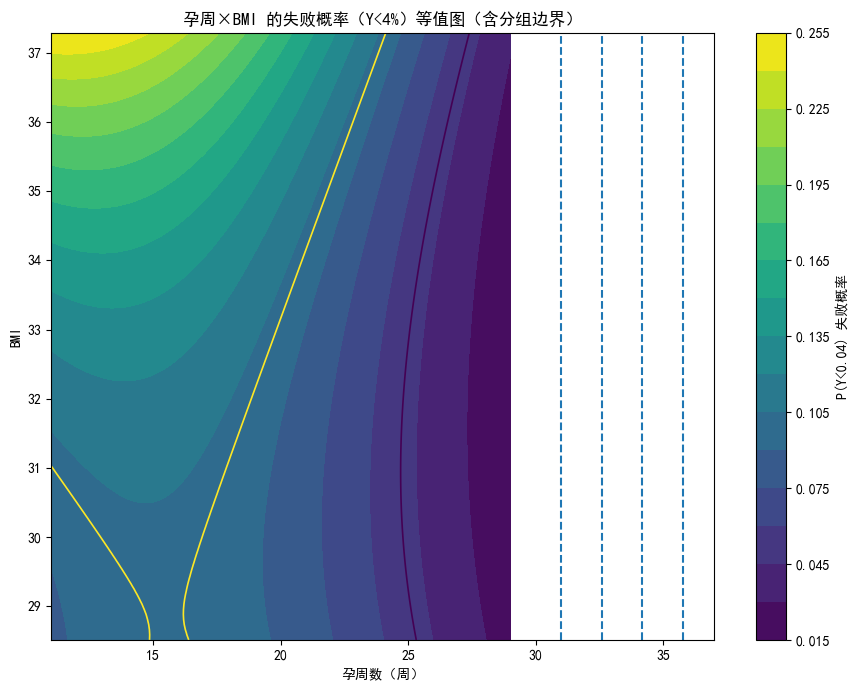

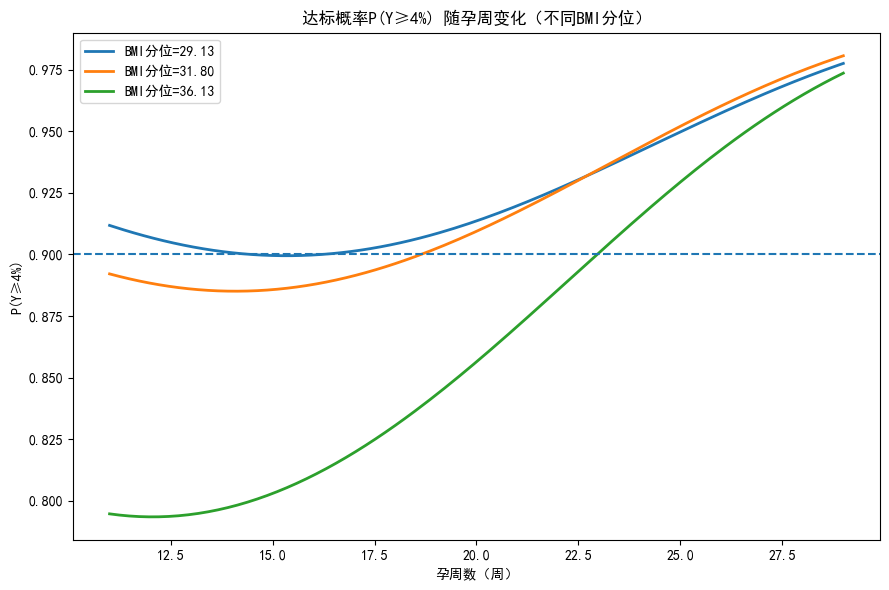

In [16]:
# import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import norm

plt.rcParams['axes.unicode_minus']=False  # 避免负号显示异常

def week_to_float(w):
    if isinstance(w, str) and "w" in w:
        try:
            w0, d = w.split("w")
            d = d.replace("+", "")
            d = int(d) if d else 0
            return int(w0) + d/7.0
        except:
            return np.nan
    try:
        return float(w)
    except:
        return np.nan

def logit(p):
    p = np.clip(p, 1e-6, 1-1e-6)
    return np.log(p/(1-p))

def earliest_week_for_q(beta_hat, sigma_hat, bmi, z_thr, w_min, w_max, q=0.90, step=0.05):
    ws = np.arange(w_min, w_max+step, step)
    Xg = np.column_stack([np.ones_like(ws), ws, np.full_like(ws, bmi), ws**2, np.full_like(ws, bmi**2), ws*bmi])
    zhat = Xg @ beta_hat
    prob = 1 - norm.cdf((z_thr - zhat)/sigma_hat)
    ok = ws[prob >= q]
    return (ok[0], prob) if ok.size>0 else (np.nan, prob)

def main(excel_path="附件.xlsx", q=0.90, n_groups=5):
    male = pd.read_excel(excel_path, sheet_name="男胎检测数据")
    male["BMI"] = male["体重"] / ((male["身高"]/100.0)**2)
    male["孕周数"] = male["检测孕周"].apply(week_to_float)
    df = male[["孕周数","BMI","Y染色体浓度"]].dropna().copy()
    df["Y染色体浓度"] = df["Y染色体浓度"].clip(1e-6, 1-1e-6)
    df["z"] = logit(df["Y染色体浓度"])
    df["w"] = df["孕周数"]; df["b"] = df["BMI"]
    X = np.column_stack([np.ones(len(df)), df["w"], df["b"], df["w"]**2, df["b"]**2, df["w"]*df["b"]])
    beta_hat = np.linalg.lstsq(X, df["z"], rcond=None)[0]
    z_pred = X @ beta_hat
    resid = df["z"] - z_pred
    sigma_hat = resid.std(ddof=X.shape[1])
    z_thr = logit(0.04)

    # 连续BMI上的w*(b)
    b_grid = np.linspace(np.percentile(df["b"], 5), np.percentile(df["b"], 95), 200)
    w_star = []
    for b in b_grid:
        w_val, _ = earliest_week_for_q(beta_hat, sigma_hat, b, z_thr, float(df["w"].min()), float(df["w"].max()), q=q)
        w_star.append(w_val)
    w_star = np.array(w_star)

    # 决策树自动分组
    mask = ~np.isnan(w_star)
    tree = DecisionTreeRegressor(max_leaf_nodes=n_groups, random_state=0)
    tree.fit(b_grid[mask].reshape(-1,1), w_star[mask])

    def extract_thresholds(decision_tree):
        t = decision_tree.tree_
        thr = []
        def dfs(node):
            if t.feature[node] != -2:
                thr.append(t.threshold[node])
                dfs(t.children_left[node])
                dfs(t.children_right[node])
        dfs(0)
        return sorted(thr)

    bounds = [float(b_grid[mask].min())] + extract_thresholds(tree) + [float(b_grid[mask].max())]
    bounds = [round(float(x),2) for x in bounds]

    rows = []
    for i in range(len(bounds)-1):
        lo, hi = bounds[i], bounds[i+1]
        mid = (lo+hi)/2.0
        w_rec, _ = earliest_week_for_q(beta_hat, sigma_hat, mid, z_thr, float(df["w"].min()), float(df["w"].max()), q=q)
        # 以组上界评估失败概率（更保守）
        Xc = np.array([1.0, w_rec, hi, w_rec**2, hi**2, w_rec*hi])
        zhat = Xc @ beta_hat
        fail_prob = norm.cdf((z_thr - zhat)/sigma_hat)
        rows.append({
            "组次": i+1,
            "BMI区间": f"[{lo}, {hi})" if i < len(bounds)-2 else f"[{lo}, {hi}]",
            "组内中位BMI": round(mid,2),
            "推荐NIPT孕周(满足{:.0f}%达标)".format(q*100): None if np.isnan(w_rec) else round(float(w_rec),2),
            "在推荐孕周于上界BMI的失败率(%)": None if np.isnan(w_rec) else round(float(fail_prob*100),2),
            "组内样本量": int(((df["b"]>=lo)&(df["b"]<hi)).sum() if i < len(bounds)-2 else ((df["b"]>=lo)&(df["b"]<=hi)).sum())
        })
    group_table = pd.DataFrame(rows)
    print("q2_group_table.csv",group_table)
    # 系数与指标
    coef_df = pd.DataFrame({"变量":["常数","孕周","BMI","孕周^2","BMI^2","孕周×BMI"], "系数估计":beta_hat})
    coef_df.to_csv("q2_logit_coef.csv", index=False, encoding="utf-8-sig")
    print("q2_logit_coef.csv",coef_df)
    aaa = pd.DataFrame({
        "残差标准差_logit":[sigma_hat],
        "阈值z值":[z_thr],
        "孕周范围":[f"{df['w'].min():.2f}-{df['w'].max():.2f}"],
        "BMI范围":[f"{df['b'].min():.2f}-{df['b'].max():.2f}"]
    })

    print("q2_metrics.csv",aaa)
    # 图A
    plt.figure(figsize=(9,6))
    plt.plot(b_grid, w_star, linewidth=2)
    for t in bounds[1:-1]:
        plt.axvline(t, linestyle="--")
    plt.title("BMI 与 推荐最早达标孕周（q={:.0f}%）及自动分组边界".format(q*100))
    plt.xlabel("BMI"); plt.ylabel("推荐最早达标孕周（周）")
    plt.tight_layout(); plt.savefig("q2_figA_bmi_to_week.png", dpi=180)

    # 图B：失败概率等值图
    w_grid = np.linspace(df["w"].min(), df["w"].max(), 120)
    b_grid2 = np.linspace(np.percentile(df["b"],5), np.percentile(df["b"],95), 120)
    WW, BB = np.meshgrid(w_grid, b_grid2)
    Xmesh = np.column_stack([np.ones(WW.size), WW.ravel(), BB.ravel(), (WW**2).ravel(), (BB**2).ravel(), (WW*BB).ravel()])
    Zhat = Xmesh @ beta_hat
    FAIL = norm.cdf((z_thr - Zhat)/sigma_hat).reshape(WW.shape)

    plt.figure(figsize=(9,7))
    cs = plt.contourf(WW, BB, FAIL, levels=18)
    cbar = plt.colorbar(cs); cbar.set_label("P(Y<0.04) 失败概率")
    plt.contour(WW, BB, FAIL, levels=[0.05, 0.10], linewidths=1.2)
    for t in bounds[1:-1]:
        plt.axvline(t, linestyle="--", ymin=0, ymax=1)
    plt.title("孕周×BMI 的失败概率（Y<4%）等值图（含分组边界）")
    plt.xlabel("孕周数（周）"); plt.ylabel("BMI")
    plt.tight_layout(); plt.savefig("q2_figB_risk_contour.png", dpi=180)

    # 图C：不同BMI分位的达标概率-孕周曲线
    plt.figure(figsize=(9,6))
    for b in np.quantile(df["b"], [0.1, 0.5, 0.9]):
        ws = np.linspace(df["w"].min(), df["w"].max(), 150)
        Xg = np.column_stack([np.ones_like(ws), ws, np.full_like(ws, b), ws**2, np.full_like(ws, b**2), ws*b])
        zhat = Xg @ beta_hat
        prob = 1 - norm.cdf((z_thr - zhat)/sigma_hat)
        plt.plot(ws, prob, linewidth=2, label="BMI分位={:.2f}".format(float(b)))
    plt.axhline(q, linestyle="--")
    plt.title("达标概率P(Y≥4%) 随孕周变化（不同BMI分位）")
    plt.xlabel("孕周数（周）"); plt.ylabel("P(Y≥4%)"); plt.legend()
    plt.tight_layout(); plt.savefig("q2_figC_prob_curves.png", dpi=180)


if __name__ == "__main__":
    main(excel_path=r'D:\desk\CUMCM2025Problems\C题\附件.xlsx', q=0.90, n_groups=5)

问题三

问题3_模型系数显著性：
                  变量      系数     标准误       t值      p值  下限95%CI  上限95%CI
0                常数 -5.3774  2.2578  -2.3818  0.0174  -9.8027  -0.9522
1                孕周 -0.2876  0.0463  -6.2085  0.0000  -0.3784  -0.1968
2               BMI  0.2118  0.0784   2.7015  0.0070   0.0581   0.3655
3              孕周^2  0.0050  0.0009   5.4203  0.0000   0.0032   0.0068
4             BMI^2 -0.0016  0.0008  -1.9891  0.0469  -0.0032  -0.0000
5            孕周×BMI  0.0018  0.0011   1.6427  0.1007  -0.0003   0.0039
6            标准化:年龄 -0.0446  0.0136  -3.2828  0.0011  -0.0712  -0.0180
7            标准化:身高  0.3197  0.1423   2.2468  0.0249   0.0408   0.5987
8            标准化:体重 -0.6400  0.2582  -2.4784  0.0133  -1.1460  -0.1339
9   标准化:13号染色体的GC含量 -0.0162  0.0193  -0.8394  0.4014  -0.0541   0.0217
10  标准化:18号染色体的GC含量 -0.0031  0.0190  -0.1605  0.8725  -0.0404   0.0343
11  标准化:21号染色体的GC含量  0.0137  0.0181   0.7578  0.4487  -0.0217   0.0491
12   标准化:被过滤掉读段数的比例  0.0235  0.0135   1.7361  0.0828  -0.0030  

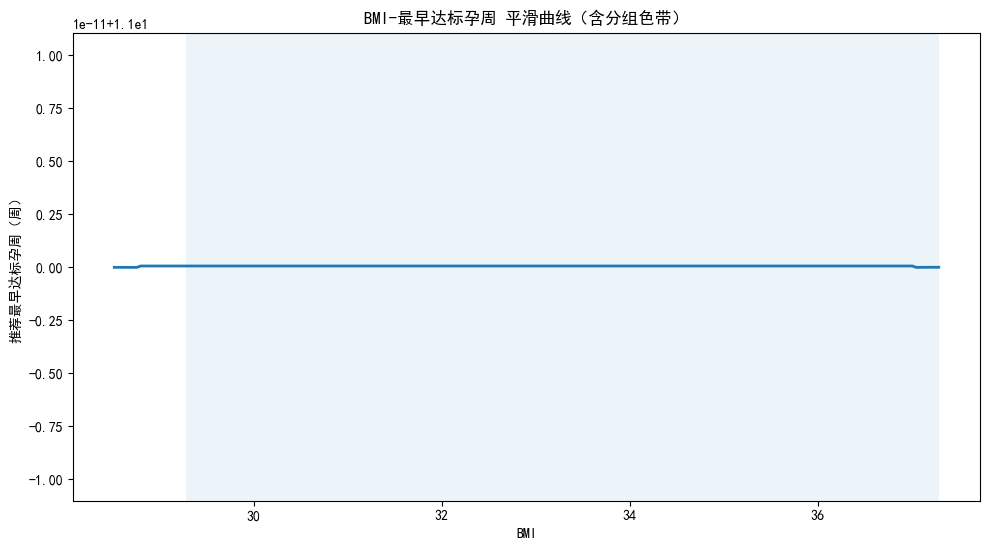

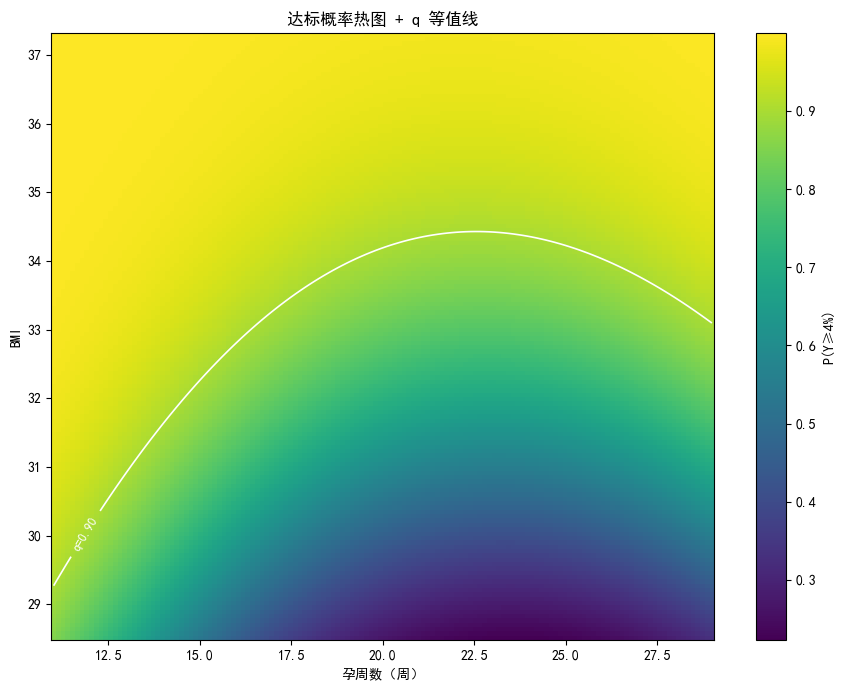

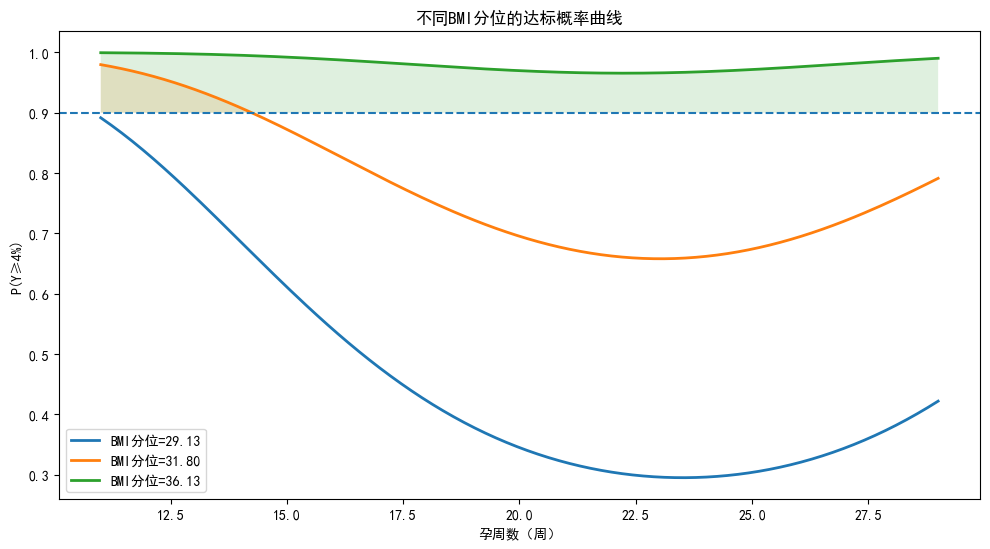

In [20]:
# -*- coding: utf-8 -*-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import norm, t
from scipy.signal import savgol_filter

plt.rcParams['axes.unicode_minus'] = False

# ------------ 公共函数 ------------
def week_to_float(w):
    if isinstance(w, str) and "w" in w:
        try:
            w0, d = w.split("w")
            d = d.replace("+","")
            d = int(d) if d else 0
            return int(w0) + d/7.0
        except:
            return np.nan
    try:
        return float(w)
    except:
        return np.nan

def logit(p):
    p = np.clip(p, 1e-6, 1-1e-6)
    return np.log(p/(1-p))

def build_design(w, b, extra_std=None):
    base = np.column_stack([np.ones_like(w), w, b, w**2, b**2, w*b])
    if extra_std is None:
        return base
    if extra_std.ndim == 1:
        extra_std = extra_std.reshape(1,-1)
    if extra_std.shape[0] == 1:
        extra_std = np.repeat(extra_std, repeats=len(w), axis=0)
    return np.column_stack([base, extra_std])

# ------------ 数据读取 ------------
file_path = r"D:\desk\CUMCM2025Problems\C题\附件.xlsx"
raw = pd.read_excel(file_path, sheet_name="男胎检测数据")
raw["BMI"] = raw["体重"] / ((raw["身高"]/100.0)**2)
raw["孕周数"] = raw["检测孕周"].apply(week_to_float)

extra_cols_all = [
    "年龄","身高","体重",
    "13号染色体的GC含量","18号染色体的GC含量","21号染色体的GC含量",
    "被过滤掉读段数的比例","原始测序数据的总读取数（个）","原始测序数据的总读段数（个）",
    "总读取中属于参考基因组上的读段比例（%）","检测抽血次数"
]

cols = ["孕周数","BMI","Y染色体浓度"] + [c for c in extra_cols_all if c in raw.columns]
df = raw[cols].dropna().copy()
df["Y染色体浓度"] = df["Y染色体浓度"].clip(1e-6, 1-1e-6)

extra_cols = [c for c in extra_cols_all if c in df.columns]
if len(extra_cols)>0:
    scaler = StandardScaler()
    extra_std = scaler.fit_transform(df[extra_cols].to_numpy())
else:
    scaler = None
    extra_std = None

# ------------ 拟合 logit OLS ------------
z = logit(df["Y染色体浓度"].to_numpy())
X = build_design(df["孕周数"].to_numpy(), df["BMI"].to_numpy(), extra_std)
XtX = X.T @ X
XtX_inv = np.linalg.inv(XtX)
beta = XtX_inv @ X.T @ z
resid = z - X @ beta
n, p = X.shape
sigma2 = (resid @ resid) / (n-p)
sigma = np.sqrt(sigma2)
z_thr = logit(0.04)

def prob_reach(w, b, extra_std_block=None, sigma_scale=1.0):
    Xp = build_design(np.array(w), np.array(b), extra_std_block)
    zhat = Xp @ beta
    return 1 - norm.cdf((z_thr - zhat)/(sigma*sigma_scale))

# ------------ 连续曲线 w*(b) ------------
q = 0.90
b_grid = np.linspace(np.percentile(df["BMI"],5), np.percentile(df["BMI"],95), 220)
w_grid = np.linspace(df["孕周数"].min(), df["孕周数"].max(), 360)

if len(extra_cols)>0:
    med_extra = np.median(df[extra_cols].to_numpy(), axis=0, keepdims=True)
    med_extra_std = scaler.transform(med_extra)
else:
    med_extra_std = None

def earliest_week_given_b(bv, q=0.90, sigma_scale=1.0):
    ws = w_grid
    bs = np.full_like(ws, bv)
    p = prob_reach(ws, bs, med_extra_std, sigma_scale=sigma_scale)
    ok = ws[p >= q]
    return ok[0] if ok.size>0 else np.nan

w_star = np.array([earliest_week_given_b(bv, q) for bv in b_grid])

# CART 分组
mask = ~np.isnan(w_star)
tree = DecisionTreeRegressor(max_leaf_nodes=5, random_state=0)
tree.fit(b_grid[mask].reshape(-1,1), w_star[mask])
def extract_thresholds(dt):
    t = dt.tree_
    thr = []
    def dfs(node):
        if t.feature[node] != -2:
            thr.append(t.threshold[node])
            dfs(t.children_left[node]); dfs(t.children_right[node])
    dfs(0); return sorted(thr)
bounds = [float(b_grid[mask].min())] + extract_thresholds(tree) + [float(b_grid[mask].max())]
bounds = [round(x,2) for x in bounds]
# ------------ 指标输出 ------------
from scipy.stats import t

# 系数显著性
XtX = X.T @ X
XtX_inv = np.linalg.inv(XtX)
se = np.sqrt(np.diag(sigma2 * XtX_inv))
tstat = beta / se
pval = 2*(1 - t.cdf(np.abs(tstat), df=n-p))
coef_names = ["常数","孕周","BMI","孕周^2","BMI^2","孕周×BMI"] + [f"标准化:{c}" for c in extra_cols]
coef_df = pd.DataFrame({
    "变量": coef_names,
    "系数": beta,
    "标准误": se,
    "t值": tstat,
    "p值": pval,
    "下限95%CI": beta - 1.96*se,
    "上限95%CI": beta + 1.96*se
})

# 核心拟合指标
metrics = pd.DataFrame({
    "样本量n":[n], "参数数p":[p],
    "R2":[1 - (resid@resid)/(((z-z.mean())**2).sum())],
    "Adj-R2":[1 - (1-R2)*(n-1)/(n-p)],
    "sigma(logit域)":[sigma],
    "AIC":[AIC], "BIC":[BIC],
    "孕周覆盖":[f"{df['孕周数'].min():.2f}-{df['孕周数'].max():.2f}"],
    "BMI覆盖":[f"{df['BMI'].min():.2f}-{df['BMI'].max():.2f}"]
})

print("问题3_模型系数显著性：\n", coef_df.round(4))
print("\n问题3_拟合与信息准则指标：\n", metrics)

# ---- 组级指标增强 ----
group_ext = []
for i in range(len(bounds)-1):
    lo, hi = bounds[i], bounds[i+1]
    in_group = (df["BMI"]>=lo) & (df["BMI"]<(hi if i<len(bounds)-2 else hi+1e-9))
    sub = df.loc[in_group].copy()
    if len(sub)==0:
        continue
    # 推荐孕周
    ws = w_grid
    mean_probs = []
    for wv in ws:
        pr = prob_reach(np.full(len(sub), wv),
                        sub["BMI"].to_numpy(),
                        scaler.transform(sub[extra_cols].to_numpy()) if len(extra_cols)>0 else None)
        mean_probs.append(pr.mean())
    mean_probs = np.array(mean_probs)
    ok = ws[mean_probs>=q]
    w_rec = ok[0] if ok.size>0 else np.nan
    group_ext.append({
        "组次":i+1,
        "BMI区间":f"[{lo},{hi}]",
        "样本量":len(sub),
        "推荐孕周":round(w_rec,2) if not np.isnan(w_rec) else None,
        "推荐孕周的平均达标比例(%)":round(mean_probs[ws==w_rec][0]*100,2) if not np.isnan(w_rec) else None
    })

group_df = pd.DataFrame(group_ext)
print("\n问题3_BMI分组增强指标：\n", group_df)

# ------------ 可视化 ------------
# 图1：平滑曲线 + 色带
plt.figure(figsize=(10,5.6))
w_smooth = savgol_filter(np.where(np.isnan(w_star), np.nanmedian(w_star), w_star), 15, 2)
plt.plot(b_grid, w_smooth, linewidth=2)
for i in range(len(bounds)-1):
    plt.axvspan(bounds[i], bounds[i+1], alpha=0.08)
plt.title("BMI-最早达标孕周 平滑曲线（含分组色带）")
plt.xlabel("BMI"); plt.ylabel("推荐最早达标孕周（周）")
plt.tight_layout(); plt.show()

# 图2：概率热图
W, B = np.meshgrid(
    np.linspace(df["孕周数"].min(), df["孕周数"].max(), 140),
    np.linspace(np.percentile(df["BMI"],5), np.percentile(df["BMI"],95), 140)
)
P = prob_reach(W.ravel(), B.ravel(), med_extra_std).reshape(W.shape)
plt.figure(figsize=(9,7))
pc = plt.pcolormesh(W, B, P, shading="auto")
cb = plt.colorbar(pc); cb.set_label("P(Y≥4%)")
cs = plt.contour(W, B, P, levels=[q], linewidths=1.2, colors="white")
plt.clabel(cs, fmt={q: f"q={q:.2f}"}, inline=True, fontsize=9)
plt.title("达标概率热图 + q 等值线")
plt.xlabel("孕周数（周）"); plt.ylabel("BMI")
plt.tight_layout(); plt.show()

# 图3：分位数曲线填充
plt.figure(figsize=(10,5.6))
ws = np.linspace(df["孕周数"].min(), df["孕周数"].max(), 160)
for bv in np.quantile(df["BMI"], [0.1, 0.5, 0.9]):
    pr = prob_reach(ws, np.full_like(ws, bv), med_extra_std)
    plt.plot(ws, pr, linewidth=2, label=f"BMI分位={bv:.2f}")
    plt.fill_between(ws, q, pr, where=(pr>=q), alpha=0.15)
plt.axhline(q, linestyle="--")
plt.title("不同BMI分位的达标概率曲线")
plt.xlabel("孕周数（周）"); plt.ylabel("P(Y≥4%)")
plt.legend(); plt.tight_layout(); plt.show()


问题四

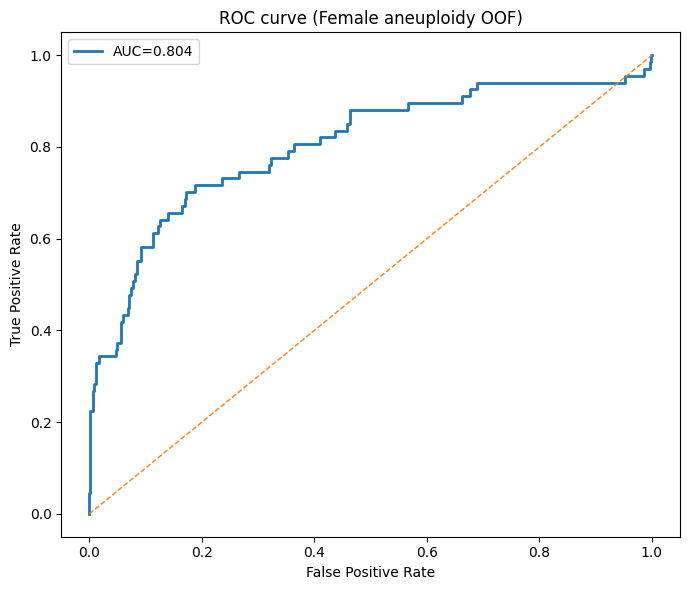

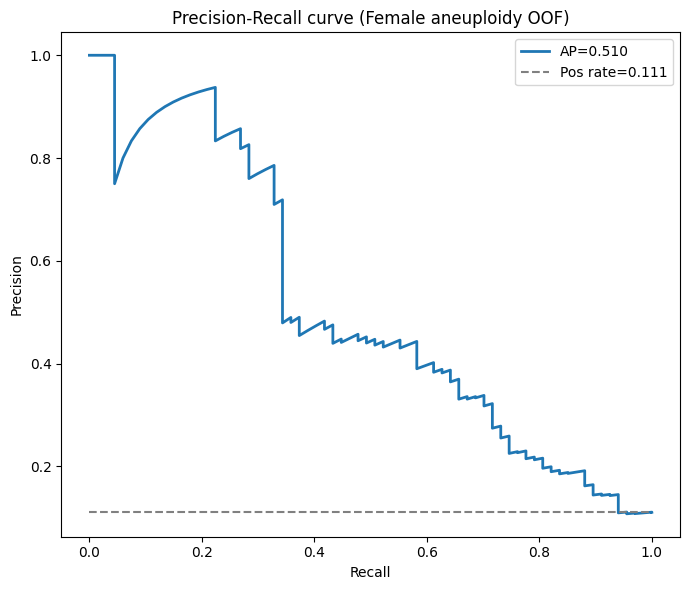

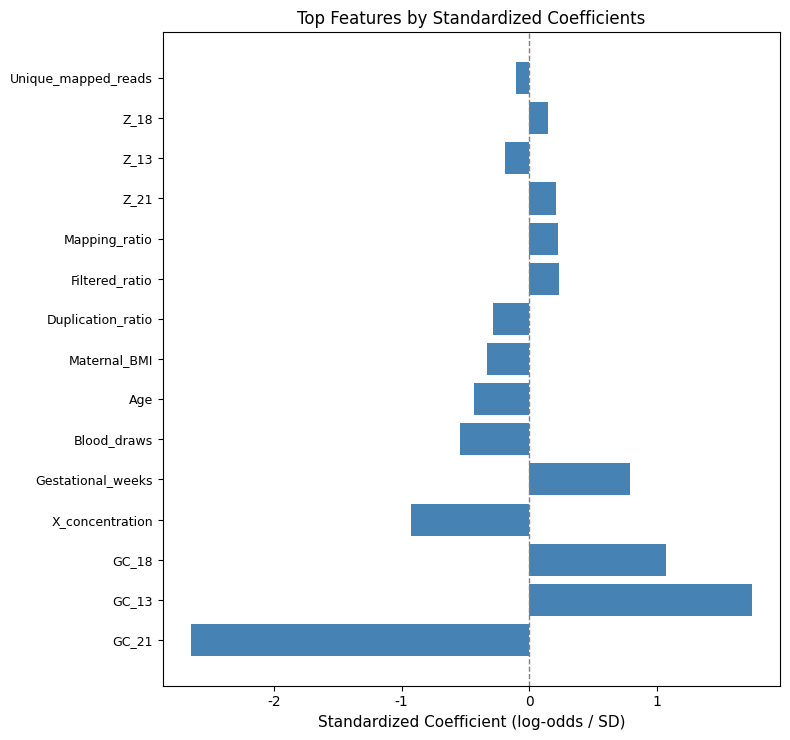


=== Overall (OOF, threshold=0.5) ===
 AUC_ROC  AP_PR  Accuracy  Precision  Recall    F1  Positives  Negatives
  0.8038 0.5101    0.7736     0.2892  0.7164 0.412         67        538

=== Best threshold (Youden) metrics ===
 BestThreshold_Youden    ACC  Precision  Recall     F1  TP  FP  TN  FN
               0.5393 0.8149     0.3381  0.7015 0.4563  47  92 446  20

=== Top coefficients (standardized) ===
         特征   标准化系数  OR(每+1SD)
21号染色体的GC含量 -2.6535     0.0704
13号染色体的GC含量  1.7469     5.7370
18号染色体的GC含量  1.0726     2.9230
     X染色体浓度 -0.9230     0.3973
        孕周数  0.7897     2.2028
     检测抽血次数 -0.5410     0.5822
         年龄 -0.4350     0.6472
      孕妇BMI -0.3306     0.7185
    重复读段的比例 -0.2840     0.7527
 被过滤掉读段数的比例  0.2334     1.2629


In [32]:
# -*- coding: utf-8 -*-

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
)

# ---------- 可调参数 ----------
FILE_PATH = r"D:\desk\CUMCM2025Problems\C题\附件.xlsx"        # 改成你的 Excel 路径或把脚本与附件放一起
SHEET_NAME = "女胎检测数据"
N_SPLITS = 5                   # 交叉验证折数
TOPN_COEF = 15                 # 系数条形图显示前N个
OUTDIR = "./"                  # 输出目录

# ---------- Matplotlib 基本设置（避免中文字体报错） ----------
plt.rcParams['font.sans-serif']=['SimHei'] #用来正常显示中文标签
plt.rcParams['axes.unicode_minus']=False #用来正常显示负号 #有中文出现的情况，需要u'内容'

# ---------- 工具函数 ----------
def week_to_float(w):
    """将如 '13w+5' -> 13 + 5/7，或已是数字的直接转为 float。"""
    if isinstance(w, str) and "w" in w:
        try:
            w0, d = w.split("w")
            d = d.replace("+", "")
            d = int(d) if d else 0
            return int(w0) + d/7.0
        except Exception:
            return np.nan
    try:
        return float(w)
    except Exception:
        return np.nan

# ---------- 读数与清洗 ----------
df_raw = pd.read_excel(FILE_PATH, sheet_name=SHEET_NAME).copy()
# 标签：是否存在“染色体的非整倍体”
df_raw["label"] = (~df_raw["染色体的非整倍体"].isna()).astype(int)
# 孕周数
df_raw["孕周数"] = df_raw["检测孕周"].apply(week_to_float)

# 备选特征列（存在即用）
CAND_FEATURES = [
    "X染色体的Z值","13号染色体的Z值","18号染色体的Z值","21号染色体的Z值",
    "X染色体浓度",
    "13号染色体的GC含量","18号染色体的GC含量","21号染色体的GC含量","GC含量",
    "原始读段数","唯一比对的读段数","在参考基因组上比对的比例",
    "重复读段的比例","被过滤掉读段数的比例",
    "孕妇BMI","年龄","检测抽血次数","孕周数"
]
FEATURES = [c for c in CAND_FEATURES if c in df_raw.columns]

use_cols = FEATURES + ["label"]
data = df_raw[use_cols].copy()

# 注意：不强行删空行，用插补器在管线里做中位数插补
X = data[FEATURES].to_numpy()
y = data["label"].to_numpy().astype(int)

# ---------- 建模管线 ----------
pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000, class_weight="balanced", solver="liblinear"))
])

# ---------- 5 折分层交叉验证，折外预测 ----------
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
oof_proba = np.zeros(len(data))
oof_pred50 = np.zeros(len(data), dtype=int)  # 阈值0.5的预测

fold_metrics = []
for fold, (tr, te) in enumerate(skf.split(X, y), 1):
    pipe.fit(X[tr], y[tr])
    proba = pipe.predict_proba(X[te])[:, 1]
    pred50 = (proba >= 0.5).astype(int)

    oof_proba[te] = proba
    oof_pred50[te] = pred50

    fpr, tpr, _ = roc_curve(y[te], proba)
    roc_auc = auc(fpr, tpr)
    prc, rec, _ = precision_recall_curve(y[te], proba)
    ap = average_precision_score(y[te], proba)

    acc = accuracy_score(y[te], pred50)
    prec = precision_score(y[te], pred50)
    rec0 = recall_score(y[te], pred50)
    f1 = f1_score(y[te], pred50)

    fold_metrics.append({
        "Fold": fold, "AUC": roc_auc, "AP": ap,
        "ACC": acc, "Precision": prec, "Recall": rec0, "F1": f1
    })

df_folds = pd.DataFrame(fold_metrics)

# ---------- 总体 OOF 指标（阈值=0.5） ----------
fpr, tpr, thr = roc_curve(y, oof_proba)
roc_auc = auc(fpr, tpr)
prc, rec, _ = precision_recall_curve(y, oof_proba)
ap = average_precision_score(y, oof_proba)

acc = accuracy_score(y, oof_pred50)
prec = precision_score(y, oof_pred50)
rec0 = recall_score(y, oof_pred50)
f1 = f1_score(y, oof_pred50)

overall_metrics = pd.DataFrame([{
    "AUC_ROC": roc_auc,
    "AP_PR": ap,
    "Accuracy": acc,
    "Precision": prec,
    "Recall": rec0,
    "F1": f1,
    "Positives": int(y.sum()),
    "Negatives": int((1-y).sum())
}])

# ---------- 最优阈值（Youden）与混淆矩阵 ----------
youden = tpr - fpr
ix = np.argmax(youden)
best_thr = thr[ix]
oof_pred_best = (oof_proba >= best_thr).astype(int)

cm = confusion_matrix(y, oof_pred_best)
acc_b = accuracy_score(y, oof_pred_best)
prec_b = precision_score(y, oof_pred_best)
rec_b = recall_score(y, oof_pred_best)
f1_b = f1_score(y, oof_pred_best)

best_thr_metrics = pd.DataFrame([{
    "BestThreshold_Youden": best_thr,
    "ACC": acc_b, "Precision": prec_b, "Recall": rec_b, "F1": f1_b,
    "TP": int(cm[1,1]), "FP": int(cm[0,1]), "TN": int(cm[0,0]), "FN": int(cm[1,0])
}])

# ---------- 在全数据上拟合一次以得到“标准化系数/OR” ----------
pipe.fit(X, y)
lr = pipe.named_steps["lr"]
coef_std = lr.coef_.ravel()               # 标准化后的系数（每 +1 SD 的对数胜算）
odds_ratio = np.exp(coef_std)             # OR（每 +1 SD）
coef_df = pd.DataFrame({
    "特征": FEATURES, "标准化系数": coef_std, "OR(每+1SD)": odds_ratio
}).reindex(np.argsort(-np.abs(coef_std))).reset_index(drop=True)


# ---------- 可视化 1：ROC（OOF） ----------
plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve (Female aneuploidy OOF)")
plt.legend()
plt.tight_layout()
fig1_path = os.path.join(OUTDIR, "q4_fig1_roc.png")
plt.savefig(fig1_path, dpi=180)
plt.show()

# ---------- 可视化 2：PR（OOF） ----------
pos_rate = y.mean()
plt.figure(figsize=(7,6))
plt.plot(rec, prc, linewidth=2, label=f"AP={ap:.3f}")
plt.hlines(pos_rate, xmin=0, xmax=1, colors="gray", linestyles="--", label=f"Pos rate={pos_rate:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve (Female aneuploidy OOF)")
plt.legend()
plt.tight_layout()
fig2_path = os.path.join(OUTDIR, "q4_fig2_pr.png")
plt.savefig(fig2_path, dpi=180)
plt.show()

# ---------- Feature name mapping (Chinese -> English) ----------
name_map = {
    "标准化系数": "Standardized Coefficient",
    "特征": "Feature",
    "X染色体的Z值": "Z_X",
    "13号染色体的Z值": "Z_13",
    "18号染色体的Z值": "Z_18",
    "21号染色体的Z值": "Z_21",
    "X染色体浓度": "X_concentration",
    "13号染色体的GC含量": "GC_13",
    "18号染色体的GC含量": "GC_18",
    "21号染色体的GC含量": "GC_21",
    "GC含量": "GC_total",
    "原始读段数": "Raw_reads",
    "唯一比对的读段数": "Unique_mapped_reads",
    "在参考基因组上比对的比例": "Mapping_ratio",
    "重复读段的比例": "Duplication_ratio",
    "被过滤掉读段数的比例": "Filtered_ratio",
    "孕妇BMI": "Maternal_BMI",
    "年龄": "Age",
    "检测抽血次数": "Blood_draws",
    "孕周数": "Gestational_weeks"
}

# Apply mapping to feature column
coef_df_en = coef_df.copy()
coef_df_en["Feature"] = coef_df_en["特征"].map(lambda x: name_map.get(x, x))
coef_df_en = coef_df_en.rename(columns={"标准化系数": "Std_Coef", "OR(每+1SD)": "OR_per_SD"})

# ---------- Visualization 3: Standardized coefficients bar chart (English) ----------
topN = min(TOPN_COEF, len(coef_df_en))
plt.figure(figsize=(8, 0.4*topN + 1.5))

vals = coef_df_en["Std_Coef"].values[:topN]
names = coef_df_en["Feature"].values[:topN]
ypos = np.arange(topN)

plt.barh(ypos, vals, color="steelblue")
plt.yticks(ypos, names, fontsize=9)
plt.axvline(0, linestyle="--", linewidth=1, color="gray")

plt.xlabel("Standardized Coefficient (log-odds / SD)", fontsize=11)
plt.title("Top Features by Standardized Coefficients", fontsize=12)
plt.tight_layout()

fig3_path = os.path.join(OUTDIR, "q4_fig3_coef_en.png")
plt.savefig(fig3_path, dpi=180)
plt.show()


# ---------- 结果摘要 ----------
print("\n=== Overall (OOF, threshold=0.5) ===")
print(overall_metrics.round(4).to_string(index=False))
print("\n=== Best threshold (Youden) metrics ===")
print(best_thr_metrics.round(4).to_string(index=False))
print("\n=== Top coefficients (standardized) ===")
print(coef_df.head(10).round(4).to_string(index=False))



In [26]:
vals


array([-2.65346278,  1.74692843,  1.07260943, -0.92300449,  0.78970941,
       -0.54097763, -0.43503299, -0.33060104, -0.2840384 ,  0.23339558,
        0.22480992,  0.21363091, -0.188276  ,  0.14497169, -0.10095387])